# Mushroom : Supervised Learning 
## Agorithm : Classifiction / KNN
### Feature
1. Cap Shape: شکل کلاهک 
2. Cap Surface: سطح کلاهک
3. Cap Color: رنگ کلاهک
4. Bruises: کبودی
5. odor: خیلی مهم بو
6. gill-attachment: اتصال تیغه ها 
7. gill-spacing: فاصله تیغه ها
8. gill-size: اندازه تیغه ها 
9. gill-color: رنگ تیغه ها 
10. stalk-shape: شکل ساقه 
11. stalk-root: ریشه ساقه 
12. stalk-surface-above-ring: سطح ساقه بالای حلقه
13. stalk-surface-below-ring: سطح ساقه زیر حلقه
14. stalk-color-above-ring: رنگ ساقه بالای حلقه 
15. stalk-color-below-ring: رنگ ساقه زیر حلقه
16. veil-type: نوع پرده 
17. veil-color: رنگ پرده 
18. ring-number: تعداد حلقه 
19. ring-type: نوع حلقه
20. spore-print-color: رنگ اسپور
21. population: میزان فراوانی 
22. habitat: محل رشد 
### Label(Class)
1.  edible: خوراکی 
2.  poisonous: سمی
### Code Structure
1.  Laibrary
2.  Load_data
3.  Algorithm   
4.  Evaluation
5.  Result

## Laibrary

In [11]:
import pandas as pd     
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier 
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, zero_one_loss, confusion_matrix , ConfusionMatrixDisplay

# Load_data

In [12]:
def load_data(data):
    columns = [ "class", "cap-shape", "cap-surface", "cap-color", "bruises",
                "odor", "gill-attachment", "gill-spacing", "gill-size", "gill-color",
                "stalk-shape", "stalk-root", "stalk-surface-above-ring", 
                "stalk-surface-below-ring", "stalk-color-above-ring",
                "stalk-color-below-ring", "veil-type", "veil-color", 
                "ring-number", "ring-type",
                "spore-print-color", "population", "habitat" ]
    # Read Data
    dataset = pd.read_csv(data, 
                      header=None,
                      names=columns)
    
    # Data and label
    dataset_encoded = dataset.apply(LabelEncoder().fit_transform)

    X = dataset_encoded.drop('class', axis=1)
    y = dataset_encoded['class']
    

    # Train and Test 
    x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)
    
    # Result
    return x_train, x_test, y_train, y_test


# Algorithm

In [13]:
def algorithm(x_train, y_train):
    
    # Object
    clf = KNeighborsClassifier(n_neighbors=5) # تعداد KNN
    rf = RandomForestClassifier()
    svm = SVC(kernel='poly')
    gnb = GaussianNB()

    params_rf = {"n_estimators" : [8 , 13 , 18 , 23 , 28] , 
                "max_depth" : [10 , 16 , 24 , 35 , 48] , 
                "min_samples_split" : [4 , 7 , 9 , 11]}
    grid_rf = GridSearchCV(estimator=rf , param_grid= params_rf , cv=3)

    # Train
    clf.fit(x_train, y_train)# متد کار train 
    rf.fit(x_train , y_train)
    gnb.fit(x_train , y_train)
    grid_rf.fit(x_train , y_train)
    svm.fit(x_train , y_train)

    # Result    
    return clf, rf, gnb, grid_rf, svm

# Evaluation 

In [14]:
def Evaluation(algorithm ,x_test, y_test):

    # label algorithm (Object)    
    y_pred = algorithm.predict(x_test)

    # accuracy_score
    acc = accuracy_score(y_test,y_pred)

    # zero_one_loss
    loss = zero_one_loss(y_test,y_pred)

    # 
    cm = confusion_matrix(y_test , y_pred)
    disply = ConfusionMatrixDisplay(confusion_matrix= cm , display_labels= algorithm.classes_)

    # Result    
    print("accuracy: {:.2f}".format(acc*100))
    print("loss: {:.2f}".format(loss*100))

    # Chart
    disply.plot()
    plt.show()
    # print(f"accuracy +  loss = {(acc + loss)*100}")
    # print("prob: ", prob)


# Result

In [15]:
data = r"Dataset\Mushroom\agaricus-lepiota.data"

x_train, x_test, y_train, y_test = load_data(data)

clf, rf, gnb, grid_rf, svm = algorithm(x_train, y_train)

KNeighborsClassifier
accuracy: 99.63
loss: 0.37


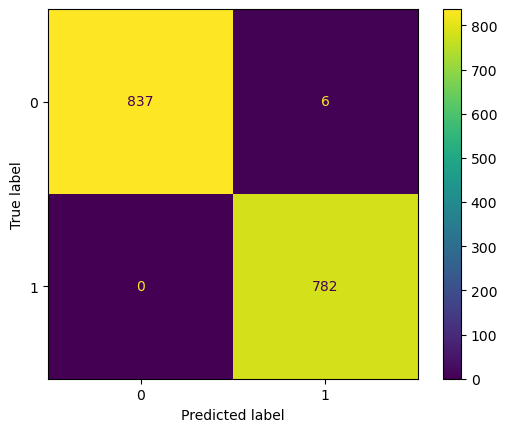

In [16]:
print("KNeighborsClassifier")
Evaluation(clf, x_test, y_test)

RandomForestClassifier
accuracy: 100.00
loss: 0.00


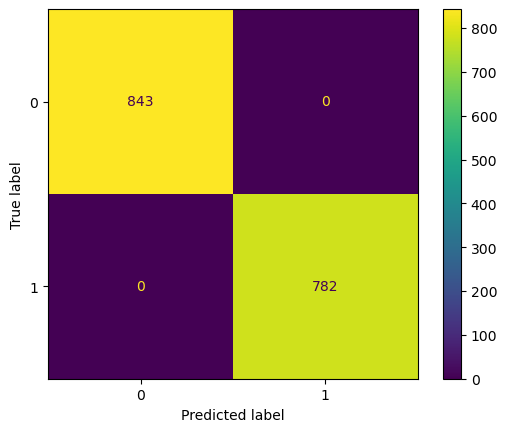

In [17]:
print("RandomForestClassifier")
Evaluation(rf, x_test, y_test)

SVC
accuracy: 100.00
loss: 0.00


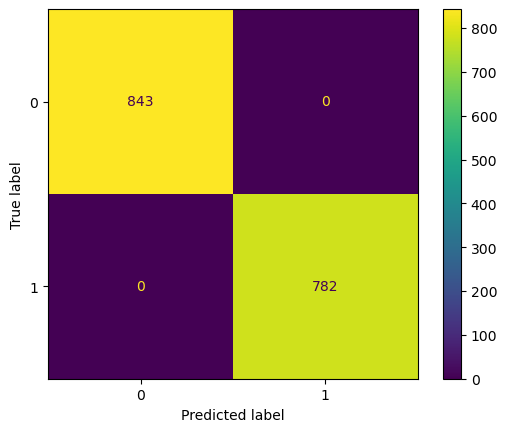

In [18]:
print("SVC")
Evaluation(svm, x_test, y_test)

GaussianNB
accuracy: 92.18
loss: 7.82


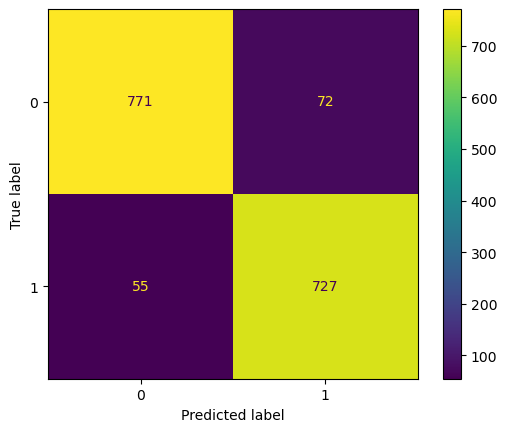

In [19]:
print("GaussianNB")
Evaluation(gnb, x_test, y_test)

GridSearchCV
accuracy: 100.00
loss: 0.00


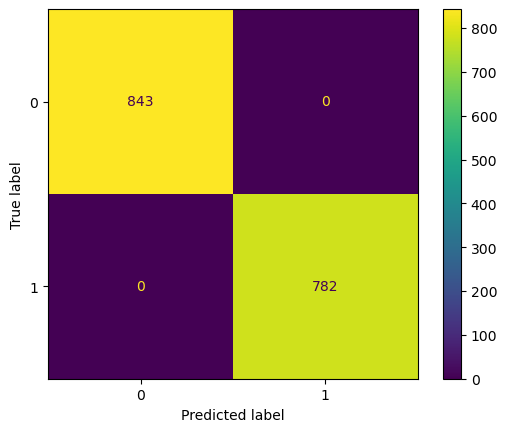

In [20]:
print("GridSearchCV")
Evaluation(grid_rf, x_test, y_test)